# Lab Assignment 3 - Time-Series Analytics
**Exploratory Analysis, Trend Visualization and Forecasting of IoT Sensor Data**

| | |
|---|---|
| **Name** | Harshit Poonia |
| **Roll No.** | S24CSEU2835 |
| **Course** | CSET480 - IoT Analytics (Specialization Elective Lab) |
| **Program / Sem** | B.Tech - 5th Semester (Odd 2026) |
| **Faculty** | Dr Debjani Ghosh |
| **Date** | 11/09/2026 |

**Objective:** Perform exploratory analysis, trend visualization and forecasting on a 14-day IoT temperature stream - decompose it into trend / seasonal / residual, examine autocorrelation, and produce and evaluate a short-term Holt-Winters forecast.

## Software Requirements
Install `statsmodels` (pandas, numpy, matplotlib are preinstalled on Colab).

In [1]:
!pip install -q statsmodels 2>/dev/null

## Part A - Setting Up the Environment

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import warnings; warnings.filterwarnings("ignore")   # hide optimizer convergence chatter
print("All libraries imported successfully")

All libraries imported successfully


## Part B - Generating the Practice Dataset
14 days × 96 readings/day (every 15 min) = 1344 readings: a daily heating/cooling sine wave (±6 °C) + a slow warming trend (+0.25 °C/day) + Gaussian sensor noise (σ = 0.4 °C).

In [3]:
np.random.seed(7)
n_days = 14
readings_per_day = 96          # one reading every 15 minutes
n = n_days * readings_per_day
timestamps = pd.date_range("2026-08-10 00:00:00", periods=n, freq="15min")
hours = np.array([t.hour + t.minute/60 for t in timestamps])
day_index = np.arange(n) / readings_per_day
seasonal = 6 * np.sin((hours-9)/24*2*np.pi - np.pi/2)   # daily cycle
trend = 24 + 0.25*day_index                              # slow warming
noise = np.random.normal(0, 0.4, n)
df = pd.DataFrame({"timestamp": timestamps,
                   "temperature": (trend+seasonal+noise).round(2)})
df.to_csv("iot_timeseries_14day.csv", index=False)
print("Dataset created:", df.shape)

Dataset created: (1344, 2)


## Part C - Loading the Data as a Time Series
The timestamp becomes the DataFrame **index** so pandas/statsmodels understand ordering and spacing.

In [4]:
df = pd.read_csv("iot_timeseries_14day.csv", parse_dates=["timestamp"])
df = df.set_index("timestamp")
print(df.shape)
print(df.head())
print(df.index.freq)   # confirm Pandas recognizes the regular 15-min spacing

(1344, 1)
                     temperature
timestamp                       
2026-08-10 00:00:00        28.92
2026-08-10 00:15:00        27.77
2026-08-10 00:30:00        27.67
2026-08-10 00:45:00        27.50
2026-08-10 01:00:00        26.69
None


`df.index.freq` prints **None** - reading from CSV does not attach a frequency automatically. `asfreq("15min")` sets it explicitly (and would insert NaN if any timestamp were missing), which also lets Holt-Winters forecast with proper future timestamps.

In [5]:
df = df.asfreq("15min")
print("Frequency now:", df.index.freq)
print("Missing values:", df["temperature"].isna().sum())
print(df["temperature"].describe().round(2))

Frequency now: <15 * Minutes>
Missing values: 0
count    1344.00
mean       25.74
std         4.44
min        17.31
25%        21.59
50%        25.75
75%        29.84
max        34.05
Name: temperature, dtype: float64


## Part D - Visualizing the Raw Time Series

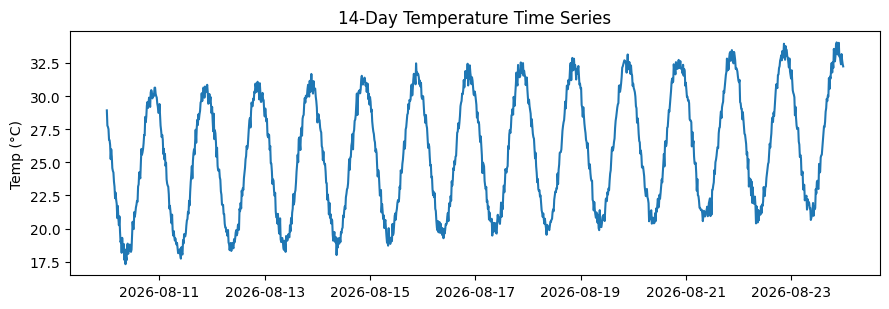

In [6]:
fig, ax = plt.subplots(figsize=(9,3.2))
ax.plot(df.index, df["temperature"])
ax.set_title("14-Day Temperature Time Series")
ax.set_ylabel("Temp (°C)")
plt.tight_layout(); plt.show()

## Part E - Trend & Seasonality Decomposition
`period=96` = 96 fifteen-minute readings per day = one seasonal cycle.

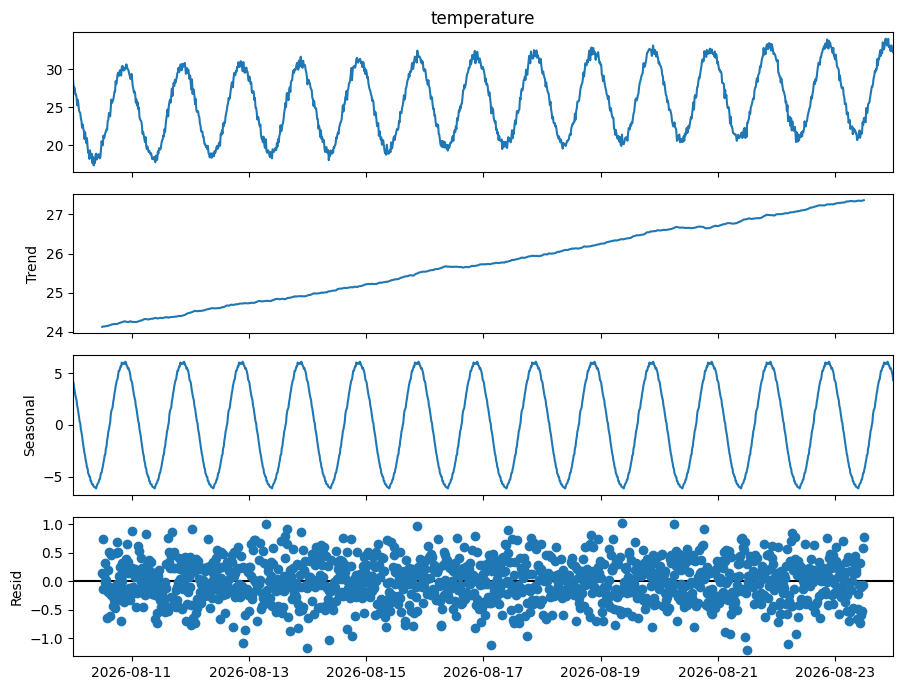

In [7]:
result = seasonal_decompose(df["temperature"], model="additive", period=96)
fig = result.plot()
fig.set_size_inches(9, 7)
plt.tight_layout(); plt.show()

In [8]:
tr = result.trend.dropna()
print(f"Trend: {tr.iloc[0]:.2f} °C -> {tr.iloc[-1]:.2f} °C  (slope ≈ {(tr.iloc[-1]-tr.iloc[0])/((tr.index[-1]-tr.index[0]).total_seconds()/86400):.3f} °C/day)")
print(f"Seasonal component range: {result.seasonal.min():.2f} to {result.seasonal.max():.2f} °C")
print(f"Seasonal peak at {result.seasonal.idxmax().time()}, trough at {result.seasonal.idxmin().time()}")
print(f"Residual: mean = {result.resid.mean():.3f} °C, std = {result.resid.std():.3f} °C")

Trend: 24.12 °C -> 27.36 °C  (slope ≈ 0.250 °C/day)
Seasonal component range: -6.14 to 6.11 °C
Seasonal peak at 21:30:00, trough at 09:30:00
Residual: mean = 0.000 °C, std = 0.371 °C


### Observation - Part E (Decomposition)
- The **trend** is a smooth, almost straight line rising from ≈ **24.1 °C to ≈ 27.4 °C** across the two weeks (≈ 0.25 °C/day) - exactly the slow "heatwave" warming built into the generator. It is undefined for the first and last half-day because the centred 96-point moving average needs a full day on each side.
- The **seasonal** component is an identical daily wave repeated every 96 readings, spanning ≈ **−6.1 °C to +6.1 °C** - the ±6 °C daily heating/cooling cycle, peaking in the evening (~21:00) and bottoming out in the morning (~09:00).
- The **residual** is centred at 0 with a std of ≈ **0.37 °C**, very close to the 0.4 °C noise injected, and shows no leftover pattern - so trend + seasonality explain almost all of the signal.
- The daily swing stays the same size while the trend rises, so the **additive** model (Observed = Trend + Seasonal + Residual) is the correct choice; a multiplicative model would only be needed if the swing grew with the level.

## Part F - Autocorrelation (ACF)

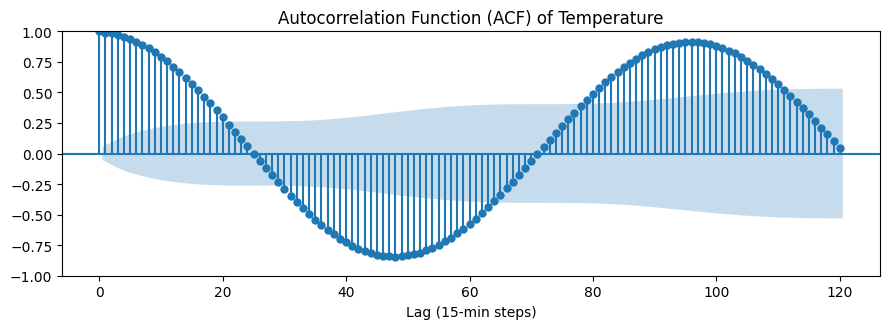

In [9]:
fig, ax = plt.subplots(figsize=(9,3.4))
plot_acf(df["temperature"], lags=120, ax=ax)
ax.set_title("Autocorrelation Function (ACF) of Temperature")
ax.set_xlabel("Lag (15-min steps)")
plt.tight_layout(); plt.show()

In [10]:
from statsmodels.tsa.stattools import acf
r = acf(df["temperature"], nlags=120)
print(f"ACF at lag 1  (15 min) : {r[1]:.3f}")
print(f"ACF minimum            : {r.min():.3f} at lag {r.argmin()} ({r.argmin()*15/60:.0f} h)")
print(f"ACF at lag 96 (24 h)   : {r[96]:.3f}")
print(f"Highest peak after lag 60: lag {60+r[60:].argmax()}")

ACF at lag 1  (15 min) : 0.989
ACF minimum            : -0.843 at lag 48 (12 h)
ACF at lag 96 (24 h)   : 0.914
Highest peak after lag 60: lag 96


### Observation - Part F (Autocorrelation)
- At very short lags the ACF is strongly positive (≈ **0.99 at lag 1**): consecutive 15-minute readings are almost the same, as expected for a slowly changing physical quantity.
- The ACF falls through zero near lag 24 (6 h) and reaches its most **negative value ≈ −0.84 at lag 48 (12 h)** - a reading is roughly the opposite of the one 12 hours earlier (day vs. night).
- It climbs back to a strong **positive peak ≈ 0.91 at lag 96 (24 h)**, statistically confirming that the pattern repeats exactly once per day.
- This wave-shaped ACF with a peak at 96 justifies the `period=96` used in decomposition (Part E) and `seasonal_periods=96` in forecasting (Part G). The peak at 96 is slightly below 1 because of noise and the warming trend.
- Almost all bars lie far outside the blue 95 % confidence band, so the correlations are highly significant - the series is far from random.

## Part G - Forecasting with Holt-Winters Exponential Smoothing
Train on the first 13 days, forecast the held-out 14th day (96 steps), and compare with the actual values.

Mean Absolute Error on held-out day: 0.35 °C


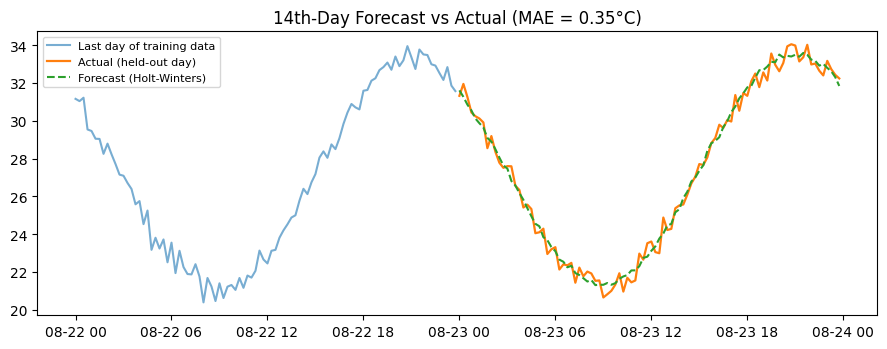

In [11]:
period = 96
train = df["temperature"].iloc[:-period]   # first 13 days
test  = df["temperature"].iloc[-period:]   # last day (held out)
model = ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=period)
fitted = model.fit()
forecast = fitted.forecast(period)
mae = np.mean(np.abs(forecast.values - test.values))
print(f"Mean Absolute Error on held-out day: {mae:.2f} °C")

fig, ax = plt.subplots(figsize=(9,3.6))
ax.plot(train.index[-period:], train.values[-period:], alpha=0.6, label="Last day of training data")
ax.plot(test.index, test.values, linewidth=1.6, label="Actual (held-out day)")
ax.plot(test.index, forecast.values, linestyle="--", label="Forecast (Holt-Winters)")
ax.set_title(f"14th-Day Forecast vs Actual (MAE = {mae:.2f}°C)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### Experiment - removing seasonality (`seasonal=None`)

MAE with seasonal='add' : 0.35 °C
MAE with seasonal=None  : 9.34 °C  (~27x worse)


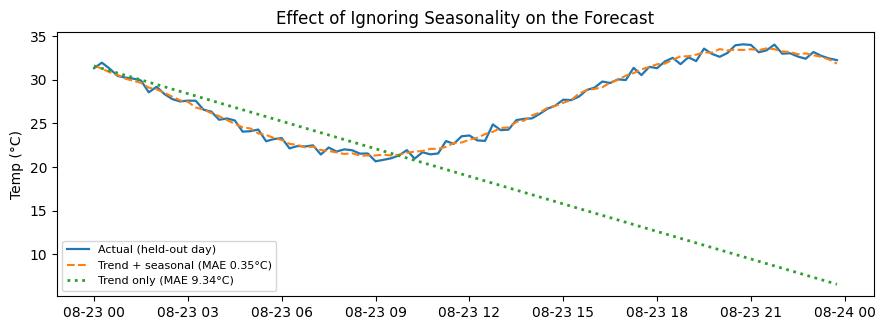

In [12]:
model_ns  = ExponentialSmoothing(train, trend="add", seasonal=None)
fitted_ns = model_ns.fit()
forecast_ns = fitted_ns.forecast(period)
mae_ns = np.mean(np.abs(forecast_ns.values - test.values))
print(f"MAE with seasonal='add' : {mae:.2f} °C")
print(f"MAE with seasonal=None  : {mae_ns:.2f} °C  (~{mae_ns/mae:.0f}x worse)")

fig, ax = plt.subplots(figsize=(9,3.4))
ax.plot(test.index, test.values, linewidth=1.6, label="Actual (held-out day)")
ax.plot(test.index, forecast.values, "--", label=f"Trend + seasonal (MAE {mae:.2f}°C)")
ax.plot(test.index, forecast_ns.values, ":", linewidth=2, label=f"Trend only (MAE {mae_ns:.2f}°C)")
ax.set_title("Effect of Ignoring Seasonality on the Forecast"); ax.set_ylabel("Temp (°C)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### Observation - Part G (Forecast)
- Trained on 13 days, the Holt-Winters model (additive trend + additive daily seasonality) forecast the entire held-out 14th day with an **MAE ≈ 0.35 °C** - well under 1 °C and close to the sensor-noise level (σ = 0.4 °C), so the remaining error is essentially unpredictable noise.
- The dashed forecast tracks the actual night-time cooling, morning minimum and evening peak almost perfectly, because the model has learnt the level, the warming trend and the 96-step daily shape.
- With **`seasonal=None`** the MAE jumps to ≈ **9.3 °C** (~27× worse): the model can only extend the recent trend as a straight line and completely misses the ±6 °C daily swing.
- Conclusion: identifying the correct seasonal period (confirmed by the ACF) and including it in the model is essential for accurate IoT sensor forecasting.

## Result
A 14-day IoT temperature time series was decomposed into trend, seasonal and residual components; its autocorrelation structure was examined and used to confirm an exact 24-hour (lag 96) repeating cycle; and a Holt-Winters exponential-smoothing model produced a forecast for a held-out day that closely matched the true values (MAE ≈ 0.35 °C), demonstrating the complete exploratory-analysis-to-forecasting workflow for IoT sensor data using classical statistical techniques.

---
# Practice Tasks for Assessment
## Task 1 - Repeat Parts C–G for Humidity
The Part B generator is extended with a **humidity** series that is *inversely* related to temperature (humid, cool nights; dry, hot evenings) plus a slow drying trend as the heatwave builds. A separate random seed is used so the temperature column stays identical to Part B.

In [13]:
# ---- Part B (extended): add humidity, inversely related to temperature ----
np.random.seed(11)
humidity = 60 - 1.5*seasonal - 0.5*day_index + np.random.normal(0, 1.0, n)   # %RH
df2 = pd.DataFrame({"timestamp": timestamps,
                    "temperature": (trend+seasonal+noise).round(2),
                    "humidity": np.clip(humidity, 0, 100).round(2)})
df2.to_csv("iot_timeseries_14day_th.csv", index=False)
print("Dataset created:", df2.shape)

# ---- Part C: load as time series ----
dfh = pd.read_csv("iot_timeseries_14day_th.csv", parse_dates=["timestamp"]).set_index("timestamp").asfreq("15min")
print(dfh.head()); print("Freq:", dfh.index.freq)
print("Temperature–humidity correlation:", round(dfh["temperature"].corr(dfh["humidity"]), 3))

Dataset created: (1344, 3)
                     temperature  humidity
timestamp                                 
2026-08-10 00:00:00        28.92     55.39
2026-08-10 00:15:00        27.77     53.77
2026-08-10 00:30:00        27.67     54.03
2026-08-10 00:45:00        27.50     52.33
2026-08-10 01:00:00        26.69     55.47
Freq: <15 * Minutes>
Temperature–humidity correlation: -0.983


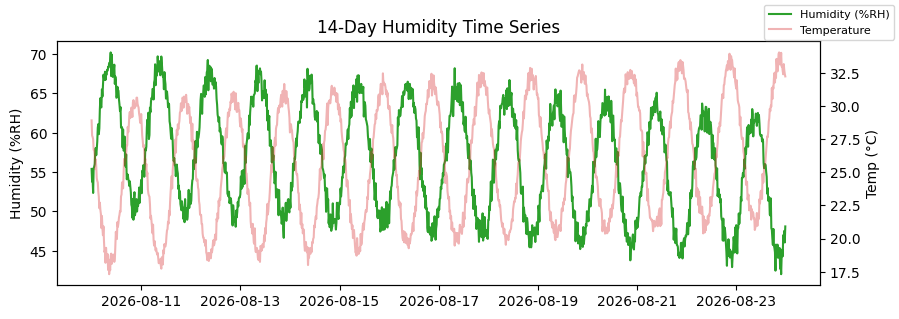

In [14]:
# ---- Part D: raw humidity series (with temperature for reference) ----
fig, ax = plt.subplots(figsize=(9,3.2))
ax.plot(dfh.index, dfh["humidity"], color="tab:green", label="Humidity (%RH)")
ax.set_ylabel("Humidity (%RH)"); ax.set_title("14-Day Humidity Time Series")
ax2 = ax.twinx(); ax2.plot(dfh.index, dfh["temperature"], color="tab:red", alpha=0.35, label="Temperature")
ax2.set_ylabel("Temp (°C)")
fig.legend(loc="upper right", fontsize=8); plt.tight_layout(); plt.show()

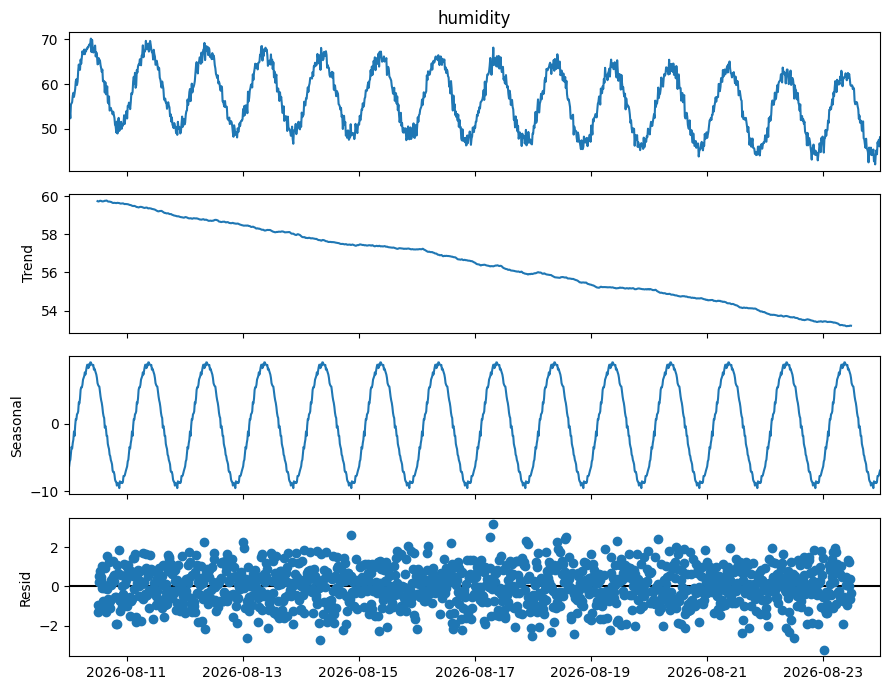

Trend: 59.75 -> 53.21 %RH
Seasonal range: -9.51 to 9.05 %RH (peak 09:00:00, trough 21:00:00)
Residual std: 0.97 %RH


In [15]:
# ---- Part E: decomposition ----
res_h = seasonal_decompose(dfh["humidity"], model="additive", period=96)
fig = res_h.plot(); fig.set_size_inches(9, 7); plt.tight_layout(); plt.show()
trh = res_h.trend.dropna()
print(f"Trend: {trh.iloc[0]:.2f} -> {trh.iloc[-1]:.2f} %RH")
print(f"Seasonal range: {res_h.seasonal.min():.2f} to {res_h.seasonal.max():.2f} %RH "
      f"(peak {res_h.seasonal.idxmax().time()}, trough {res_h.seasonal.idxmin().time()})")
print(f"Residual std: {res_h.resid.std():.2f} %RH")

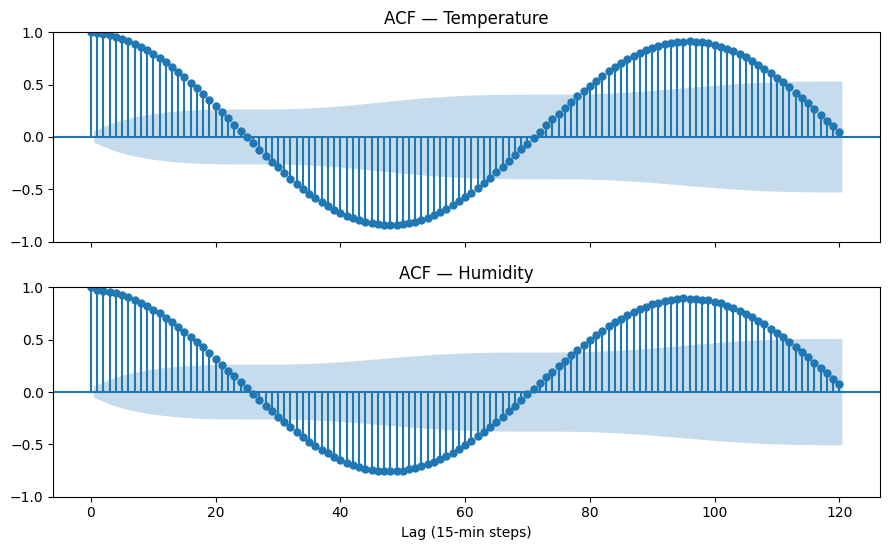

                lag1       min (lag)   lag96
Temperature    0.989    -0.843 (48)   0.914
Humidity       0.976    -0.758 (48)   0.894


In [16]:
# ---- Part F: ACF (humidity vs temperature) ----
fig, axes = plt.subplots(2, 1, figsize=(9,5.6), sharex=True)
plot_acf(dfh["temperature"], lags=120, ax=axes[0]); axes[0].set_title("ACF - Temperature")
plot_acf(dfh["humidity"],    lags=120, ax=axes[1]); axes[1].set_title("ACF - Humidity")
axes[1].set_xlabel("Lag (15-min steps)"); plt.tight_layout(); plt.show()
rh = acf(dfh["humidity"], nlags=120)
print(f"{'':12}{'lag1':>8}{'min (lag)':>16}{'lag96':>8}")
print(f"{'Temperature':12}{r[1]:8.3f}{r.min():10.3f} ({r.argmin()}){r[96]:8.3f}")
print(f"{'Humidity':12}{rh[1]:8.3f}{rh.min():10.3f} ({rh.argmin()}){rh[96]:8.3f}")

Humidity MAE on held-out day: 0.89 %RH


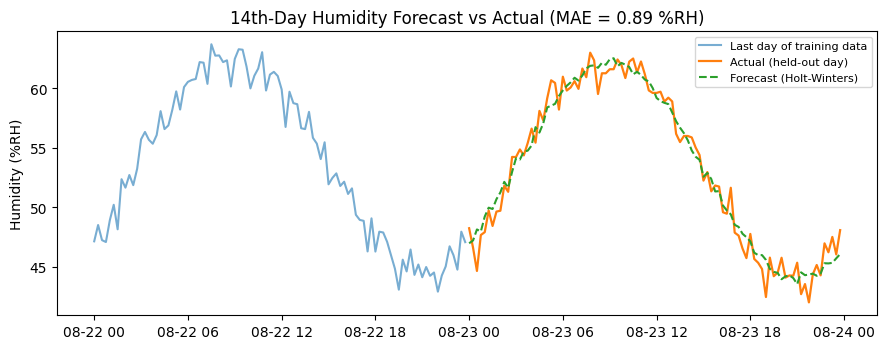

In [17]:
# ---- Part G: Holt-Winters forecast for humidity ----
train_h = dfh["humidity"].iloc[:-period]; test_h = dfh["humidity"].iloc[-period:]
fit_h = ExponentialSmoothing(train_h, trend="add", seasonal="add", seasonal_periods=period).fit()
fc_h = fit_h.forecast(period)
mae_h = np.mean(np.abs(fc_h.values - test_h.values))
print(f"Humidity MAE on held-out day: {mae_h:.2f} %RH")
fig, ax = plt.subplots(figsize=(9,3.6))
ax.plot(train_h.index[-period:], train_h.values[-period:], alpha=0.6, label="Last day of training data")
ax.plot(test_h.index, test_h.values, linewidth=1.6, label="Actual (held-out day)")
ax.plot(test_h.index, fc_h.values, linestyle="--", label="Forecast (Holt-Winters)")
ax.set_title(f"14th-Day Humidity Forecast vs Actual (MAE = {mae_h:.2f} %RH)"); ax.set_ylabel("Humidity (%RH)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### Observation - Task 1 (Humidity vs Temperature)
- Humidity is strongly **inversely** related to temperature (correlation ≈ **−0.98**): it peaks in the morning (~09:00) when it is coolest and bottoms out in the evening (~21:00) when it is hottest.
- **Seasonal period:** the same **96 steps (24 h)** - both variables are driven by the same daily solar cycle. The humidity seasonal swing is ≈ −9.5 to +9.1 %RH, and it is the mirror image (opposite phase) of the temperature wave.
- **Trend:** humidity *falls* from ≈ 59.8 to ≈ 53.2 %RH over the two weeks (air drying out as the heatwave builds), while temperature rises.
- **ACF shape:** practically identical to temperature - ≈ 0.98 at lag 1, most negative at **lag 48 (≈ −0.76)**, and a strong peak at **lag 96 (≈ 0.89)**. The ACF does not reveal the phase inversion (autocorrelation compares a series only with itself); the humidity values are slightly lower because its noise is larger relative to its signal (residual std ≈ 0.97 %RH).
- Holt-Winters with `seasonal_periods=96` again forecasts the held-out day accurately (MAE ≈ 0.89 %RH, close to the injected 1 %RH noise).

## Task 2 - Shorter Forecast Horizon (next 4 hours = 16 steps)
Using the **same trained model** from Part G (`fitted`), forecast only 16 steps ahead and recompute the MAE.

MAE - next 4 hours (16 steps): 0.286 °C
MAE - full day   (96 steps)  : 0.348 °C
  horizon  16 steps (   4 h): MAE = 0.286 °C
  horizon  32 steps (   8 h): MAE = 0.306 °C
  horizon  48 steps (  12 h): MAE = 0.347 °C
  horizon  64 steps (  16 h): MAE = 0.334 °C
  horizon  80 steps (  20 h): MAE = 0.342 °C
  horizon  96 steps (  24 h): MAE = 0.348 °C


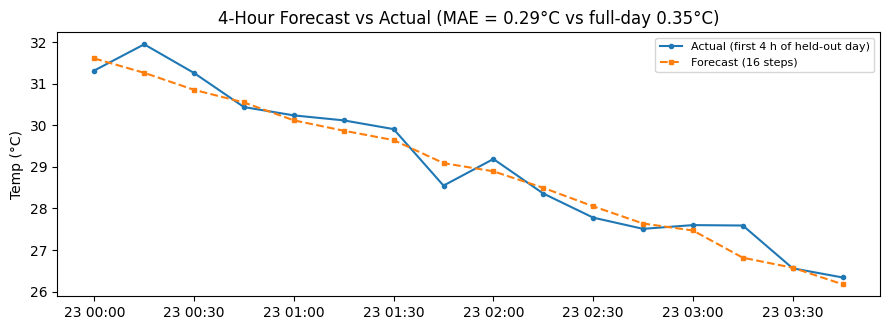

In [18]:
h = 16                                   # 4 hours x 4 readings/hour
forecast_4h = fitted.forecast(h)
mae_4h = np.mean(np.abs(forecast_4h.values - test.values[:h]))
print(f"MAE - next 4 hours (16 steps): {mae_4h:.3f} °C")
print(f"MAE - full day   (96 steps)  : {mae:.3f} °C")

# MAE for every horizon from 4 h to 24 h, to show the growth of error
horizons = range(16, 97, 16)
for hh in horizons:
    print(f"  horizon {hh:3d} steps ({hh/4:4.0f} h): MAE = {np.mean(np.abs(forecast.values[:hh]-test.values[:hh])):.3f} °C")

fig, ax = plt.subplots(figsize=(9,3.4))
ax.plot(test.index[:h], test.values[:h], "o-", ms=3, label="Actual (first 4 h of held-out day)")
ax.plot(test.index[:h], forecast_4h.values, "s--", ms=3, label="Forecast (16 steps)")
ax.set_title(f"4-Hour Forecast vs Actual (MAE = {mae_4h:.2f}°C vs full-day {mae:.2f}°C)")
ax.set_ylabel("Temp (°C)"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### Observation - Task 2 (Forecast Horizon)
The 4-hour (16-step) forecast has an **MAE ≈ 0.29 °C**, lower than the full-day (96-step) **MAE ≈ 0.35 °C**, and the error generally grows as the horizon lengthens.

**Why shorter horizons are more accurate:** each Holt-Winters step builds on the previous forecast, so small errors in the estimated level, trend slope and seasonal shape accumulate and compound the further ahead we predict. Close to the end of training, the most recent observed level is still highly informative (ACF ≈ 0.99 at short lags), but that information decays with each step, and unexpected changes (noise, weather shifts) have more time to occur. Here the gap is modest because the synthetic data is very regular and the model's error is already close to the 0.4 °C noise floor; on real sensor data the difference is usually much larger.